# Trabajo Práctico 1: Procesamiento de Datos
## Análisis exploratorio de desastres naturales (EM-DAT, 1970-2021)

**Instituto Superior Santo Domingo (ISSD).** Opción A: dataset provisto por la cátedra. Arquitectura elegida: **ETL tradicional** (`extract/`, `transform/`, `load/`).

Este notebook es la etapa de **análisis y reporte gráfico**. Toda la lógica vive en los módulos `.py` del proyecto; acá solo se llaman las funciones, se muestran los resultados y se interpretan.

**Índice**
1. Extracción e ingesta de datos
2. Transformación temporal y estacionalidad
3. Curación de variables
4. Los 5 cruces de variables
5. Conclusiones

In [18]:
import sys
from pathlib import Path

# Ruta relativa: el notebook vive en /notebooks y el proyecto está un nivel arriba.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from extract.extractor import extraer_datos, validar_carga, explorar_estructura
from transform.transformer import (
    crear_fecha, filtrar_periodo_reciente, eventos_por_anio,
    calcular_estacionalidad, tabla_anios_mes,
)
from transform.curacion import curar_variables, reporte_curacion
from transform.cruces import (
    tipo_por_continente, top_paises_por_tipo, inundaciones_por_region,
    terremotos_por_pais, terremotos_por_region, cantidad_vs_gravedad, tipo_por_mes,
)
from load.loader import (
    graficar_serie_anual, graficar_estacionalidad, graficar_heatmap_anio_mes,
    graficar_tipo_continente, graficar_top_paises, graficar_inundaciones_region,
    graficar_terremotos, graficar_cantidad_vs_gravedad,
)

pd.set_option("display.width", 200)

## 1. Extracción e ingesta de datos

El módulo `extract/extractor.py` lee el CSV con una ruta relativa al proyecto, valida que la carga sea correcta (no vacío y con las columnas necesarias) y muestra una exploración inicial de la estructura.

In [19]:
df_bruto = extraer_datos()
validar_carga(df_bruto)
explorar_estructura(df_bruto)

Carga validada

Dimensiones: 14644 filas x 47 columnas
Rango de años: 1970 - 2021

Tipos de datos:
Dis No                                 str
Year                                 int64
Seq                                  int64
Glide                                  str
Disaster Group                         str
Disaster Subgroup                      str
Disaster Type                          str
Disaster Subtype                       str
Disaster Subsubtype                    str
Event Name                             str
Country                                str
ISO                                    str
Region                                 str
Continent                              str
Location                               str
Origin                                 str
Associated Dis                         str
Associated Dis2                        str
OFDA Response                          str
Appeal                                 str
Declaration                            st

**Apreciación crítica.**

- El dataset tiene **14.644 filas y 47 columnas**. Por lo tanto esta adentro del rango manejable por Pandas.
- **Cobertura temporal:** el archivo cubre **1970-2021**, no 1900-2021 como figura en el nombre del dataset de la consigna. Todo el análisis de este informe se limita, entonces, a esos 52 años.
- Hay muchas columnas con muchisimos nulos (por ejemplo, costos de reconstrucción, ayuda recibida y daños asegurados, con entre 93 % y 100 % de nulos), que no vamos a usar. Las variables clave para el análisis (`Disaster Type`, `Country`, `Region`, `Continent`, `Start Year`) están completas, mientras que `Start Month` tiene unos 270 nulos y `Total Deaths` alrededor de un 30 %.
- No hay filas duplicadas, lo cual indica que el identificador `Dis No` es confiable.

## 2. Transformación temporal

`crear_fecha` unifica `Start Year`, `Start Month` y `Start Day` en una única columna `fecha` de tipo `datetime64`. Criterios de imputación:

- **Día faltante** → se usa el día 1 (el análisis es mensual).
- **Día inválido** (por ejemplo, 31 de septiembre de 1992) → día 1 del mismo mes.
- **Mes faltante** → la fecha queda como `NaT`. No se imputa un mes para no sesgar la estacionalidad (por ejemplo, inflando enero).

In [20]:
df = crear_fecha(df_bruto)
print("Tipo de la columna fecha:", df["fecha"].dtype)
print(f"Con fecha: {df['fecha'].notna().sum()} | Sin fecha (mes faltante): {df['fecha'].isna().sum()}")
df[["Start Year", "Start Month", "Start Day", "fecha"]].head()

Tipo de la columna fecha: datetime64[us]
Con fecha: 14376 | Sin fecha (mes faltante): 268


,Start Year,Start Month,Start Day,fecha
0,1970,1.0,4.0,1970-01-04
1,1970,1.0,NaN,1970-01-01
2,1970,9.0,NaN,1970-09-01
3,1970,11.0,12.0,1970-11-12
4,1970,4.0,13.0,1970-04-13


### 2.1 Evolución anual de los eventos

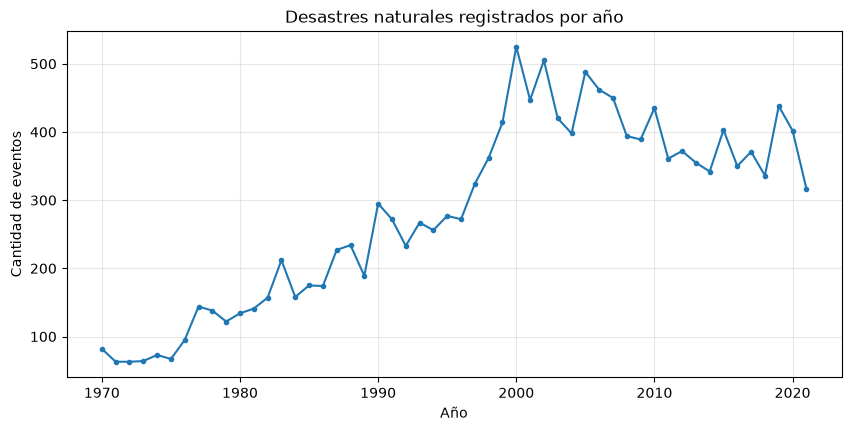

In [21]:
serie = eventos_por_anio(df)
fig = graficar_serie_anual(serie)
plt.show()

**Apreciación crítica.** El registro pasa de 82 eventos en 1970 a un máximo de **525 en el año 2000**, y después se estabiliza en torno a 400 por año (promedio de 399 entre 2002 y 2021, contra 136 entre 1970 y 1989). Si leyeramos esto como "hay casi el triple de desastres" sería un error: el salto refleja que **mejoró la cobertura del registro** (más países reportando, mejores sistemas de información), y no solo que ocurran más desastres. La caída de 2021 (317 eventos) tampoco es real: los datos llegan hasta el 7 de octubre de 2021.

### 2.2 Estacionalidad

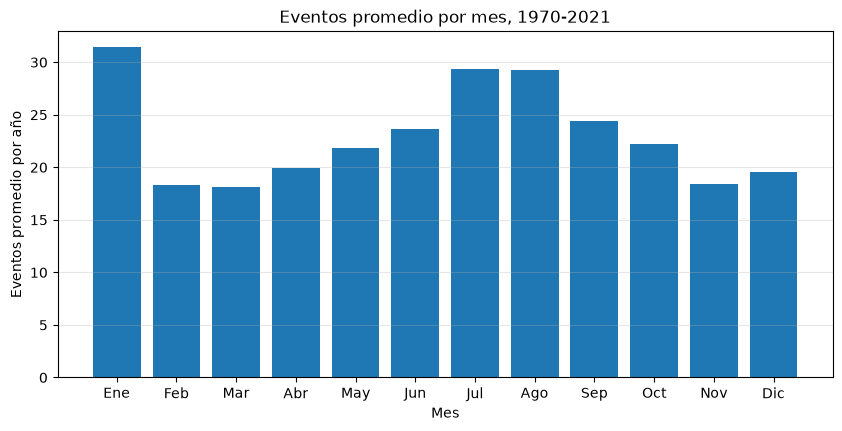

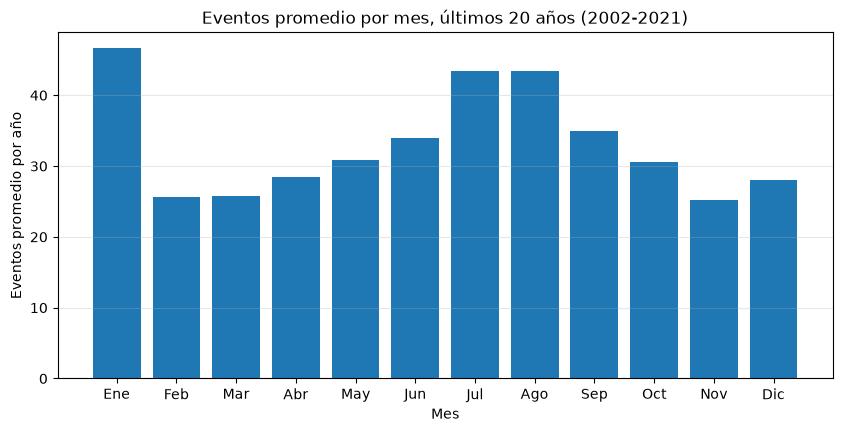

,mes,eventos,promedio_por_anio
0,Ene,933,46.6
1,Feb,512,25.6
2,Mar,517,25.8
3,Abr,567,28.4
4,May,617,30.8
5,Jun,680,34.0
6,Jul,869,43.4
7,Ago,867,43.4
8,Sep,699,35.0
9,Oct,611,30.6


In [22]:
est_total = calcular_estacionalidad(df)
reciente = filtrar_periodo_reciente(df, anios=20)   # 2002-2021
est_reciente = calcular_estacionalidad(reciente)

fig = graficar_estacionalidad(est_total, "Eventos promedio por mes, 1970-2021")
plt.show()
fig = graficar_estacionalidad(est_reciente, "Eventos promedio por mes, últimos 20 años (2002-2021)")
plt.show()
est_reciente

**Apreciación crítica.** En los dosperíodos aparece el mismo patrón de **dos picos**: enero (31,4 eventos por año en el total y 46,6 en los últimos 20 años) y julio-agosto (29,4 y 43,4). Los meses más tranquilos son febrero-marzo y noviembre (alrededor de 18 por año en el total). Los valores del período reciente son más altos en todos los meses, lo que le da la razon al crecimiento del registro visto antes.

Para entender de dónde salen los picos, abrimos la estacionalidad por tipo de desastre (últimos 20 años):

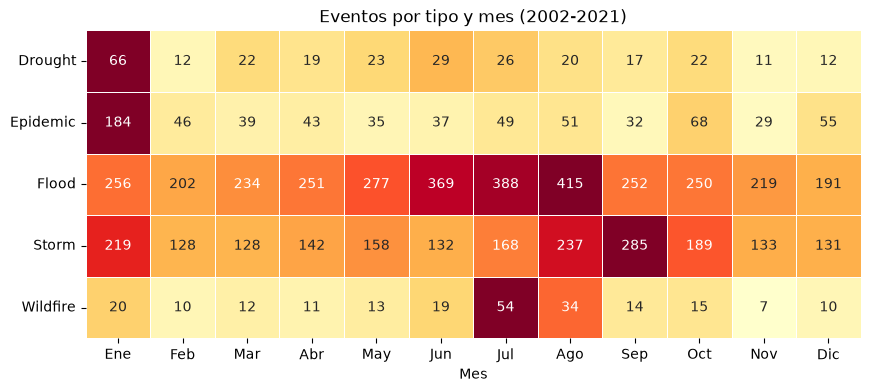

In [23]:
import seaborn as sns

tabla_tm = tipo_por_mes(reciente, ["Flood", "Storm", "Epidemic", "Drought", "Extreme temperature", "Wildfire"])

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(tabla_tm.div(tabla_tm.max(axis=1), axis=0), annot=tabla_tm, fmt="d",
            cmap="YlOrRd", linewidths=0.5, cbar=False, ax=ax)
ax.set_title("Eventos por tipo y mes (2002-2021)")
ax.set_xlabel("Mes")
ax.set_ylabel("")
plt.show()

- **Julio-agosto** coincide con el pico de **inundaciones** (junio-agosto, hasta 415 eventos en agosto) y el de incendios forestales (julio). Las **tormentas** tienen su máximo en agosto-septiembre (237 y 285), compatible con la temporada de huracanes y tifones en el norte.
- Las **temperaturas extremas** muestran dos máximos opuestos: enero (95) y julio (81), es decir, olas de frío y olas de calor.
- **Enero merece cautela.** Lo explican sobre todo las **epidemias** (184 eventos, contra 29 a 68 en el resto de los meses) y las **sequías** (66, contra 11 a 29). Una hipótesis, que habría que verificar con la fuente, es que los eventos de larga duración se registran con inicio "1 de enero" por convención. Esto da a entender que una parte del pico de enero puede ser un artefacto del registro y no un fenómeno estacional real.

### 2.3 Heatmap año × mes (últimos 20 años)

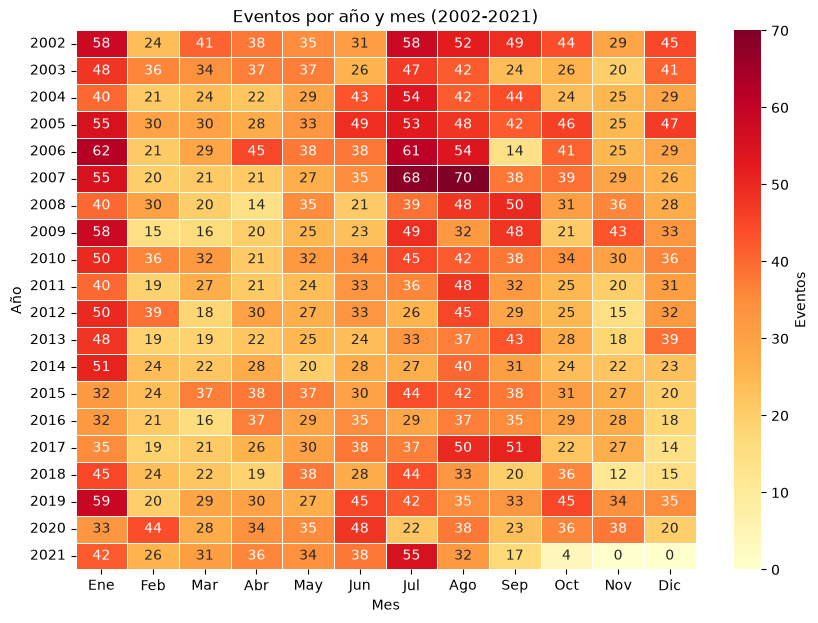

In [24]:
matriz = tabla_anios_mes(reciente)
fig = graficar_heatmap_anio_mes(matriz, "Eventos por año y mes (2002-2021)")
plt.show()

**Apreciación crítica.** El heatmap confirma que enero y julio-agosto son las columnas más oscuras en la mayoría de los años (máximos de 70 eventos en agosto de 2007 y 62 en enero de 2006). No se ve una tendencia mensual muy marcada a lo largo de las dos décadas: la estacionalidad es estable, y lo que varía es la intensidad. Los últimos tres meses de 2021 aparecen casi vacíos (4 eventos en octubre y ninguno en noviembre y diciembre): esto se debe a que es el **corte del registro**, no una caída real.

## 3. Curación de variables

`curar_variables` depura las columnas de categoría y ubicación con cinco pasos: limpieza de espacios, estandarización de nombres de países, corrección de regiones, marcado de países históricos e imputación de categorías nulas.

In [25]:
df = curar_variables(df)
reporte_curacion(df_bruto, df)

Países distintos      : 228 -> 228
Regiones distintas    : 23 -> 22
Tipos de desastre     : 14 -> 14
Tipos con espacios    : 584 -> 0
Nulos en Subtype      : 2747 -> 0
Nulos en Location     : 1346 -> 0
Registros de países históricos: 119


**Decisiones de curación y su justificación**

- **Espacios sobrantes en `Disaster Type`** (584 registros, como `"Extreme temperature "`): se eliminaron. Sin esto, un filtro como `df["Disaster Type"] == "Extreme temperature"` devolvería cero filas, sin dar ningún aviso.
- **Nombres de países:** se pasaron los nombres oficiales largos a su forma de uso común (por ejemplo, `"United States of America (the)"` → `"United States"`) y se quitó el sufijo `(the)`. La cantidad de países no cambia (228) porque no había duplicados por error de tipeo; el objetivo fue la consistencia y la legibilidad en los gráficos.
- **Región `"Russian Federation"`** (47 filas, todas de la Unión Soviética): no es una región, así que se reasignó a `"Eastern Europe"`, donde está el resto de Rusia en el dataset.
- **Países históricos** (Unión Soviética, Yugoslavia, Checoslovaquia, etc., 119 registros): se conservan porque los desastres ocurrieron, pero se marcan con la columna `pais_historico`.
- **Nulos categóricos** (`Disaster Subtype`, `Location`): se imputaron con una etiqueta explícita (`"Sin especificar"`, `"Desconocida"`).
- **Variables numéricas (muertes, afectados, daños): no se imputan.** Rellenar con 0 diría que no murió nadie donde no hay dato, y rellenar con el promedio inventaría valores muy distorsionados por unos pocos desastres gigantes.

## 4. Los 5 cruces de variables

### Cruce 1: tipo de desastre × continente

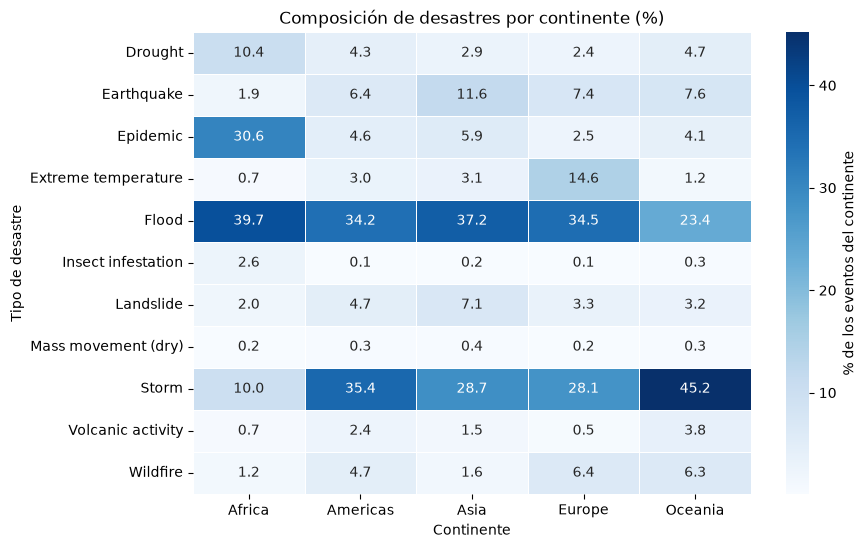

In [26]:
cruce1 = tipo_por_continente(df)
fig = graficar_tipo_continente(cruce1)
plt.show()

**Apreciación crítica.** Las **inundaciones** son el tipo más frecuente en África (39,7 %), Asia (37,2 %) y Europa (34,5 %), mientras que en Oceanía (45,2 %) y América (35,4 %) dominan las **tormentas**. Cada uno de los continentes tiene además un rasgo propio: **África concentra epidemias** (30,6 %, contra 2,5 % a 5,9 % en los demás) y más sequías (10,4 %); **Europa** destaca por las **temperaturas extremas** (14,6 %, contra 3,1 % o menos en el resto); y **Asia** por los terremotos (11,6 %). Al comparar epidemias hay que tener cuidado: que haya más registradas en África puede reflejar no solo que ocurren más, sino también diferencias en cómo se reportan. Se excluyeron los tipos con menos de 40 registros (tres tipos con 1 o 2 casos), porque con tan pocos eventos el porcentaje no es interpretable.

### Cruce 2: países con más eventos, por tipo

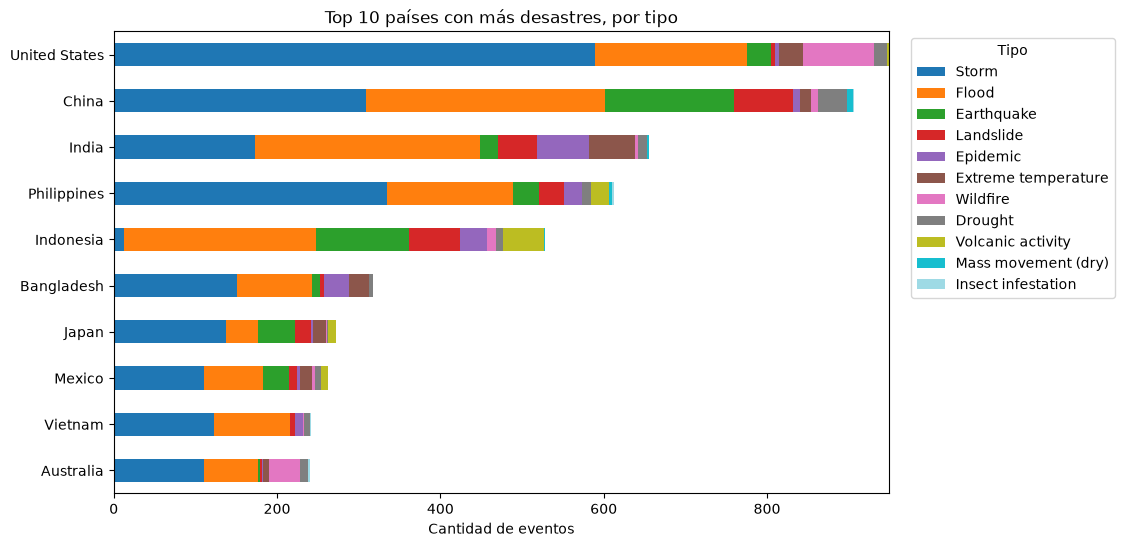

Disaster Type,Storm,Flood,Earthquake,Landslide,Epidemic,Extreme temperature,Wildfire,Drought,Volcanic activity,Mass movement (dry),Insect infestation
Country,,,,,,,,,,,
United States,589,186,30,5,5,29,87,16,2,0,0
China,309,292,158,73,8,14,8,36,0,7,1
India,173,275,22,48,64,56,4,11,0,2,1
Philippines,335,154,32,30,22,0,1,10,23,3,2
Indonesia,13,235,113,63,33,0,11,9,50,1,0
Bangladesh,151,92,9,6,30,24,0,5,0,0,0
Japan,137,40,45,19,3,16,1,1,10,0,0
Mexico,111,72,32,10,3,15,4,7,8,0,0
Vietnam,123,93,0,6,10,0,1,7,0,0,1


In [27]:
cruce2 = top_paises_por_tipo(df, n=10)
fig = graficar_top_paises(cruce2)
plt.show()
cruce2

**Apreciación crítica.** Estados Unidos (949 eventos) y China (906) lideran, y en ambos pesan mucho las tormentas. Parte del resultado se explica claramente por su **tamaño**: un país grandisimo tiene más territorio donde puede ocurrir un evento, así que el conteo bruto favorece a los países grandes. Cada país tiene además una "firma" distinta: **Indonesia** casi no registra tormentas (13) pero sí inundaciones (235), terremotos (113) y actividad volcánica (50); **Filipinas** concentra tormentas (335); y los incendios forestales pesan en **Estados Unidos** (87) y **Australia** (38). Una mejora posible sería normalizar por superficie o población.

### Cruce 3: inundaciones por región

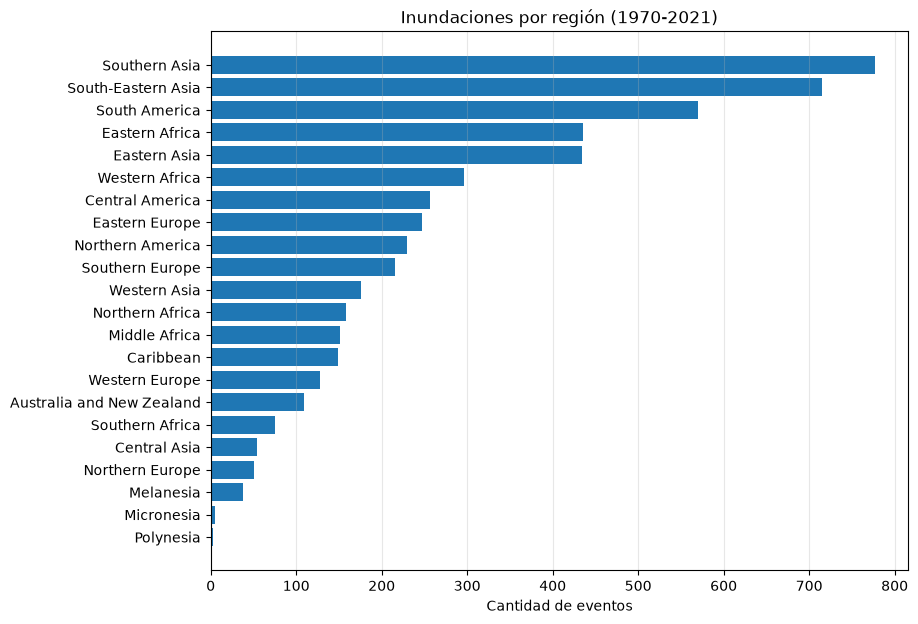

,eventos,porcentaje
Region,,
Southern Asia,777,14.7
South-Eastern Asia,715,13.6
South America,570,10.8
Eastern Africa,436,8.3
Eastern Asia,434,8.2
Western Africa,296,5.6
Central America,256,4.9
Eastern Europe,247,4.7


In [28]:
cruce3 = inundaciones_por_region(df)
fig = graficar_inundaciones_region(cruce3)
plt.show()
cruce3.head(8)

**Apreciación crítica.** **Asia Meridional (777), Sudeste Asiático (715) y Asia Oriental (434)** suman más de un tercio de todas las inundaciones registradas (36,5 %); les sigue Sudamérica (570). Es coherente con el peso de los monzones y de las grandes cuencas fluviales de la región, aunque esa explicación es una hipótesis y no algo que el dataset demuestre. En el otro extremo, las regiones insulares del Pacífico (Micronesia, Polinesia) casi no registran inundaciones.

### Cruce 4: terremotos, distribución geográfica

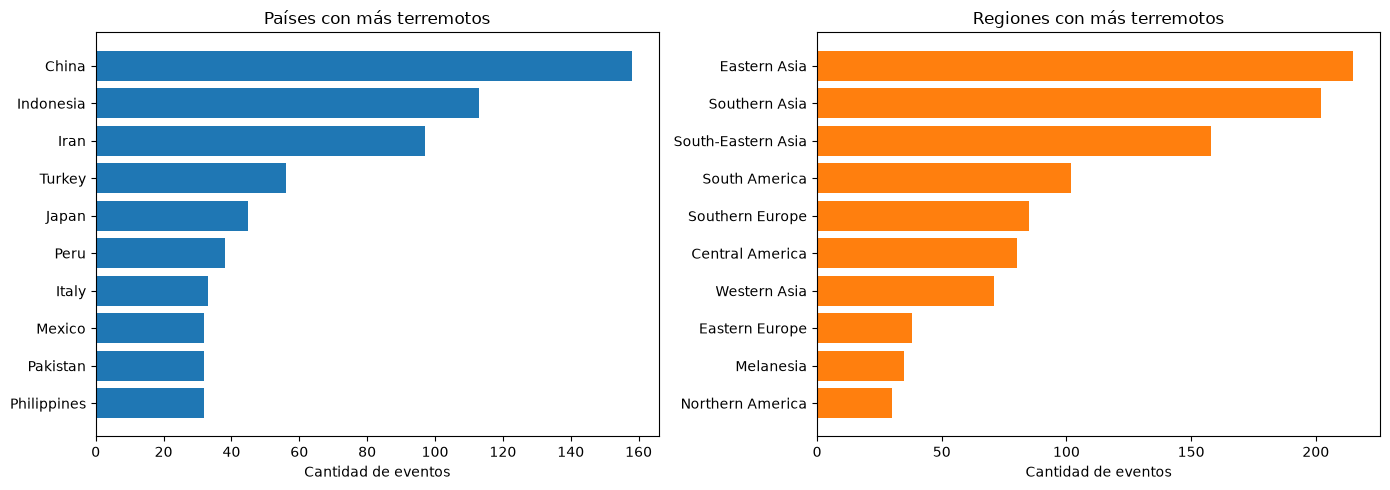

,Country,Region,eventos
0,China,Eastern Asia,158
1,Indonesia,South-Eastern Asia,113
2,Iran,Southern Asia,97
3,Turkey,Western Asia,56
4,Japan,Eastern Asia,45
5,Peru,South America,38
6,Italy,Southern Europe,33
7,Mexico,Central America,32
8,Pakistan,Southern Asia,32
9,Philippines,South-Eastern Asia,32


In [29]:
cruce4_pais = terremotos_por_pais(df, n=10)
cruce4_region = terremotos_por_region(df)
fig = graficar_terremotos(cruce4_pais, cruce4_region)
plt.show()
cruce4_pais

**Apreciación crítica.** Lideran **China (158), Indonesia (113), Irán (97), Turquía (56) y Japón (45)**. Ubicados en un mapa, los países del ranking se alinean con el **Cinturón de Fuego del Pacífico** (Japón, Indonesia, Filipinas, Perú, México) y con la franja sísmica que va de Turquía a Irán y Pakistán. A nivel regional, Asia Oriental (215) y Asia Meridional (202) encabezan la lista. Hay que recordar que esto cuenta **eventos registrados** (los que causaron daños o fueron reportados), no la actividad sísmica real, que es mucho mayor.

### Cruce 5: cantidad vs. gravedad

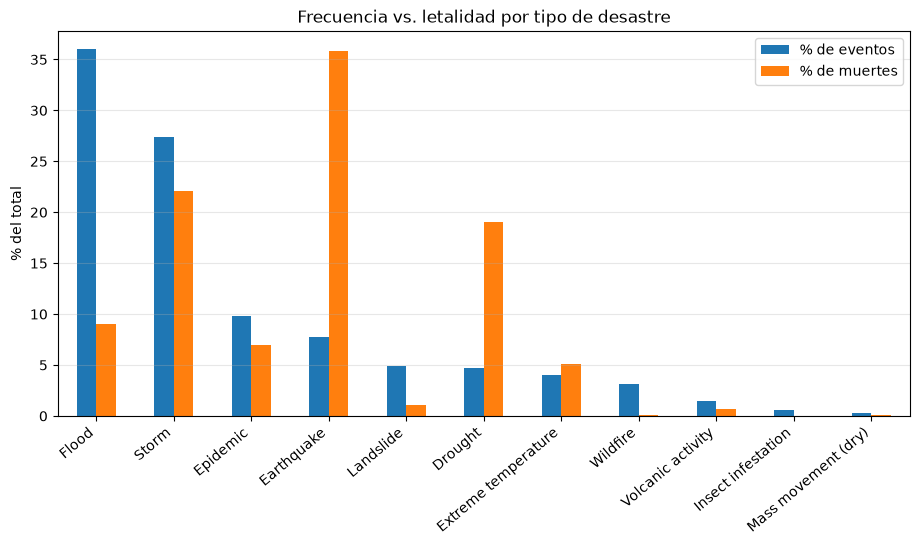

,eventos,muertes,pct_eventos,pct_muertes
Disaster Type,,,,
Flood,5272,330683.0,36.0,9.0
Storm,4005,817134.0,27.4,22.1
Epidemic,1436,259735.0,9.8,7.0
Earthquake,1137,1319284.0,7.8,35.8
Landslide,713,40737.0,4.9,1.1
Drought,685,700774.0,4.7,19.0
Extreme temperature,584,189101.0,4.0,5.1
Wildfire,452,2963.0,3.1,0.1
Volcanic activity,222,27135.0,1.5,0.7


In [30]:
cruce5 = cantidad_vs_gravedad(df)
fig = graficar_cantidad_vs_gravedad(cruce5)
plt.show()
cruce5

**Apreciación crítica.** Este es el cruce más informativo. Las **inundaciones** son el tipo más frecuente (36,0 % de los eventos) pero relativamente poco letal (9,0 % de las muertes). Los **terremotos** son apenas el 7,8 % de los eventos y concentran el **35,8 % de las muertes**; las **sequías** pasan de 4,7 % de los eventos a 19,0 % de las muertes; y los incendios forestales (3,1 % de los eventos) casi no causan muertes (0,1 %). Dos cautelas: el dato de muertes **falta en alrededor del 30 % de los registros**, y la suma está dominada por unos pocos eventos gigantes (el máximo individual es de 300.000 muertes), así que los porcentajes de terremotos y sequías dependen mucho de esos casos extremos.

## 5. Conclusiones

1. **El crecimiento del registro no equivale a más desastres.** Los eventos pasan de 82 en 1970 a unos 400 por año desde 2002, pero claramente parte de ese aumento es mejor cobertura. Cualquier análisis de tendencias debe leerse con esa salvedad.
2. **La estacionalidad tiene dos picos** (enero y julio-agosto), y el de julio-agosto se explica por fenómenos meteorológicos reconocibles (monzones, temporada de tormentas). El de enero está inflado por epidemias y sequías, y podría ser en parte un artefacto de cómo se fechan los eventos ya que por lo visto el comienzo de epidemias o sequias se suele marcar el 1 de enero.
3. **Cada continente y país tiene un perfil propio.** Las inundaciones dominan en África, Asia y Europa; las tormentas en América y Oceanía; las epidemias son un rasgo de África; y los terremotos se concentran en el Cinturón de Fuego y la franja Turquía-Irán-Pakistán.
4. **Frecuencia no es letalidad (insight accionable).** Los terremotos y las sequías son poco frecuentes pero concentran más de la mitad de las muertes. Esto se debe a la potencia de los mismos, un terremoto puede derrumbar edificios en un abrir y cerrar de ojos, esto da referencia a que no necesariamente la letalidad aumenta con la frecuencia de los desastres sino que depende de cual es el desastre.
5. **Limitaciones.** El archivo cubre 1970-2021 (no 1900); faltan muertes en alrededor del 30 % de los registros; el conteo de eventos favorece a los países grandes; y el registro llega solo hasta octubre de 2021.